In [1]:
import os
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data.dataloader import DataLoader
from torch.utils.data import random_split

from tsdart.utils import set_random_seed
from tsdart.loss import Prototypes
from tsdart.model import TSDART, TSDARTLayer, TSDARTModel, TSDARTEstimator, TSDARTModel
from tsdart.dataprocessing import Preprocessing

In [2]:
device = torch.device('cpu')

In [3]:
data = []
order = []  # keep track of which run/clone each index is

for i in range(252):
    for j in range(5):
        filename = f"./spectral_oasis/spectral_oasis_filter_RUN{i}_CLONE{j}.npy"
        try:
            arr = np.load(filename)
            #print(f"Loaded {filename} with shape {arr.shape}")
            data.append(arr)
            order.append((i, j))  # store run/clone mapping
        except FileNotFoundError:
            print(f"Missing file: {filename}")
        except Exception as e:
            print(f"Error loading {filename}: {e}")

# sanity check: print first 10 and last 10
print("First 10:", order[:10])
print("Last 10:", order[-10:])


Missing file: ./spectral_oasis/spectral_oasis_filter_RUN6_CLONE0.npy
Missing file: ./spectral_oasis/spectral_oasis_filter_RUN6_CLONE1.npy
Missing file: ./spectral_oasis/spectral_oasis_filter_RUN6_CLONE2.npy
Missing file: ./spectral_oasis/spectral_oasis_filter_RUN6_CLONE3.npy
Missing file: ./spectral_oasis/spectral_oasis_filter_RUN6_CLONE4.npy
Missing file: ./spectral_oasis/spectral_oasis_filter_RUN15_CLONE1.npy
Missing file: ./spectral_oasis/spectral_oasis_filter_RUN25_CLONE1.npy
Missing file: ./spectral_oasis/spectral_oasis_filter_RUN26_CLONE3.npy
Missing file: ./spectral_oasis/spectral_oasis_filter_RUN27_CLONE0.npy
Missing file: ./spectral_oasis/spectral_oasis_filter_RUN30_CLONE1.npy
Missing file: ./spectral_oasis/spectral_oasis_filter_RUN40_CLONE1.npy
Missing file: ./spectral_oasis/spectral_oasis_filter_RUN77_CLONE3.npy
Missing file: ./spectral_oasis/spectral_oasis_filter_RUN101_CLONE3.npy
Missing file: ./spectral_oasis/spectral_oasis_filter_RUN118_CLONE1.npy
Missing file: ./spectra

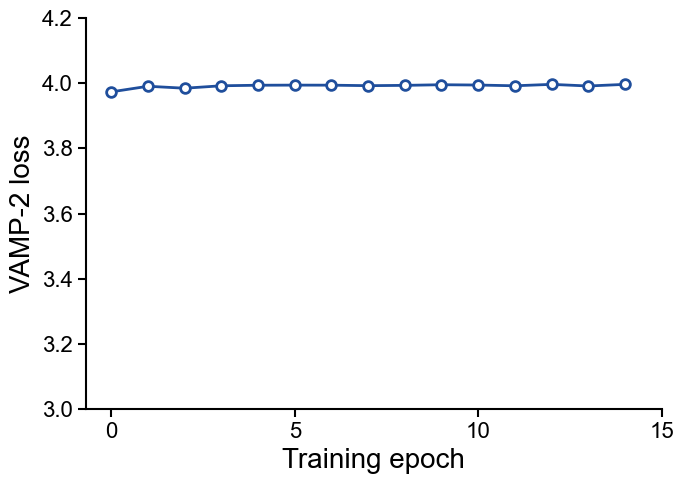

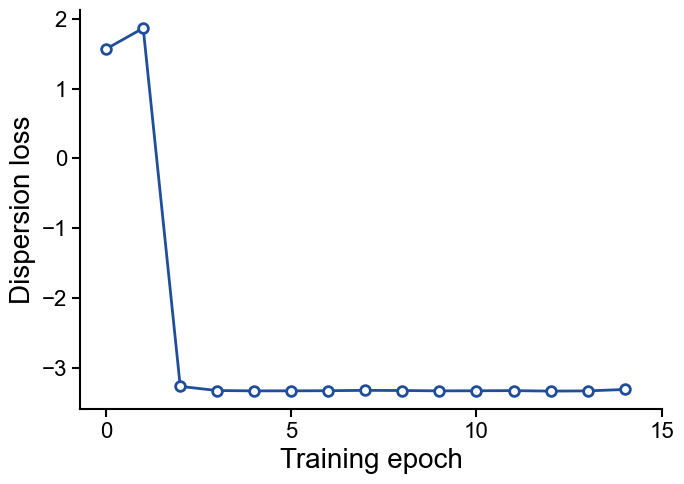

In [9]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family":       "Arial",
    "font.size":          12,
    "axes.linewidth":     1.5,
    "xtick.major.width":  1.5,
    "ytick.major.width":  1.5,
    "xtick.major.size":   6,
    "ytick.major.size":   6,
    "xtick.direction":    "out",
    "ytick.direction":    "out",
})

def plot_single_run(file_path, ylabel, color='#1F4E9C',
                    ylim=None, yticks=None, save_path=None):
    data = np.load(file_path)

    fig, ax = plt.subplots(figsize=(7, 5))

    ax.plot(data,
            linewidth=2,
            marker='o',
            markersize=7,
            markerfacecolor='white',
            markeredgecolor=color,
            markeredgewidth=2,
            color=color)

    ax.set_xlabel('Training epoch', fontsize=20)
    ax.set_ylabel(ylabel, fontsize=20)
    ax.set_xticks(np.arange(0, 20, 5))

    if ylim:   ax.set_ylim(ylim)
    if yticks is not None: ax.set_yticks(yticks)

    ax.tick_params(labelsize=16)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, format='svg', bbox_inches='tight')
    plt.show()


# VAMP-2 loss
plot_single_run(
    file_path='./ts-dar_4-state_model/validation_vamp.npy',
    ylabel='VAMP-2 loss',
    yticks=np.arange(3, 4.2, 0.2),
    save_path='./vamp2_loss.svg',
)

# Dispersion loss
plot_single_run(
    file_path='./ts-dar_4-state_model/validation_dis.npy',
    ylabel='Dispersion loss',
    save_path='./dispersion_loss.svg',
)

In [11]:
# Initialize with specified hidden layer sizes and number of output states
lobe = TSDARTLayer([2000,1000,500,250,125,50,3],n_states=4)

# Load a pre-trained model
lobe.load_state_dict(torch.load('./ts-dar_4-state_model/model_10epochs.pytorch', map_location=torch.device('cpu')))

tsdart_model = TSDARTModel(lobe=lobe)

# Use the model to transform the input data into low-dimensional representations on the surface of a hypersphere
features = tsdart_model.transform(data,return_type='hypersphere_embs')

# Use the same model to assign each frame in the input trajectory to one of the learned states
lumped_trajs = tsdart_model.transform(data,return_type='states') # State Assignment

#np.save("Mtb_state_assignment_new.npy", np.array(lumped_trajs, dtype=object))

In [12]:
# Initialize the TS-DAR Estimator to compute metastable state centers
tsdart_estimator = TSDARTEstimator(tsdart_model).fit(data)

# These scores indicate how far each point is from its assigned state's center, which helps detect rare conformations
ood_scores = tsdart_estimator.ood_scores

# Extract the learned centers (means) of each state in the latent hypersphere embedding space
state_centers = tsdart_estimator.state_centers

print(state_centers)

# Theoretical threshold (based on minimum angle between state centers)
#thres = -np.cos(sim_mat.min()/2)+1 

# Empirical threshold (based on maximum OOD score)
#thres = np.max(np.concatenate(ood_scores)) 

# NOTE: use the smaller value for thres

[[-0.8960132  -0.28750148 -0.33838323]
 [ 0.05167583 -0.15974715  0.98580444]
 [ 0.72020876 -0.5184429  -0.46099487]
 [ 0.11954185  0.97649056 -0.17937621]]


In [13]:
import numpy as np
import pandas as pd
import warnings

class StateAnalyzer:
    def __init__(self, state_centers, features, ood_scores):
        """
        Initialize the StateAnalyzer with state centers, features, and OOD scores.

        Parameters:
        - state_centers: List or array of state centers.
        - features: List of trajectories, where each trajectory is a list of feature vectors.
        - ood_scores: List of OOD scores corresponding to the features.
        """
        self.state_centers = state_centers
        self.features = features
        self.ood_scores = ood_scores
        self.flatten_features = np.concatenate(features)
        self.flatten_ood_scores = np.concatenate(ood_scores)
        self.indices = self._flatten_features()

    def _flatten_features(self):
        """
        Keep track of (traj_idx, frame_idx, flatten_idx).
        In case that different trajectories have different lengths, have careful record of the indices.

        Returns:
        - flatten_features: Flattened list of feature vectors.
        - indices: List of tuples containing (traj_idx, frame_idx, flatten_idx).
        """
        indices = []
        flatten_idx = 0
        for traj_idx, traj in enumerate(self.features):
            for frame_idx, f in enumerate(traj):
                indices.append((traj_idx, frame_idx, flatten_idx))
                flatten_idx += 1
        return indices

    def find_center_frames(self, center_idx=0, top_n=10):
        """
        Find the indices of the closest frames to each state center.

        Parameters:
        - num_centers: Number of state centers (default: 4).
        - top_n: Number of closest frames to return for each center (default: 10).

        Returns:
        - center_frames: DataFrame containing the closest frames for each state center.
        """
        results = []
        diff = np.linalg.norm(self.flatten_features - self.state_centers[center_idx], axis=1)

        # Find the indices of the top_n closest frames
        k = np.argsort(diff)[:top_n]

        # Extract trajectory, frame, and flattened indices
        closest_entries = [(center_idx, *self.indices[i]) for i in k]
        results.extend(closest_entries)

        # Create a DataFrame to store the results
        center_frames = pd.DataFrame(results, columns=["Center_Index", "Trajectory", "Frame", "Flatten_Index"])
        return center_frames

    def find_transition_states(self, state_idx_1, state_idx_2, threshold=0.25, top_n=10):
        """
        Find the indices of the transition states with the highest OOD scores between two states.

        Parameters:
        - state_idx_1: Index of the first state.
        - state_idx_2: Index of the second state.
        - threshold: Distance threshold for considering a feature as close to the midpoint (default: 0.25).
          Note: the threshold can't be larger than sqrt(2), not recommended to be larger than 1
        - top_n: Number of top transition states to return (default: 10).

        Returns:
        - selected_indices: Indices of the top transition states.
        - selected_ood_scores: OOD scores of the top transition states.
        """
        # Compute the midpoint between the two state centers and normalize it
        state_centers_mid = (self.state_centers[state_idx_1] + self.state_centers[state_idx_2]) / 2
        state_centers_mid /= np.linalg.norm(state_centers_mid)  # Normalize

        # Find indices where the feature is within the threshold distance from state_centers_mid
        close_indices = [i for i in range(len(self.flatten_features)) 
                         if np.linalg.norm(self.flatten_features[i] - state_centers_mid) < threshold]
        
        # Check if there are enough close frames
        if len(close_indices) < top_n:
            warnings.warn(
                f"Only {len(close_indices)} close frames found (requested {top_n}). "
                "Returning all available frames. Try increasing the threshold.",
                UserWarning,
            )
            top_n = len(close_indices)  # Adjust top_n to the number of available frames

        # Get the OOD scores corresponding to these indices
        ood_scores_filtered = self.flatten_ood_scores[close_indices]

        # Get the indices of the top N highest OOD scores from the selected frames
        top_n_indices = np.argsort(ood_scores_filtered)[-top_n:]

        # Retrieve the corresponding original indices
        selected_indices = [close_indices[i] for i in top_n_indices]

        # Get the corresponding OOD scores
        selected_ood_scores = self.flatten_ood_scores[selected_indices]

        # Create a DataFrame to store the results
        transition_data = {
            "State_1_Index": state_idx_1,
            "State_2_Index": state_idx_2,
            "OOD_Score": selected_ood_scores,
            "Flatten_Index": selected_indices,
            }

        # Add trajectory and frame indices if available
        if hasattr(self, 'indices'):
            transition_data["Trajectory"] = [self.indices[i][0] for i in selected_indices]
            transition_data["Frame"] = [self.indices[i][1] for i in selected_indices]

        transition_df = pd.DataFrame(transition_data)

        return transition_df

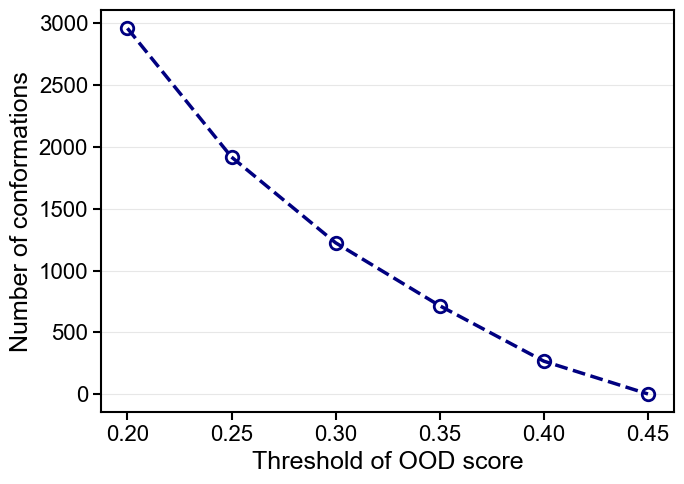

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Flatten OOD scores
all_ood = np.concatenate(ood_scores)

# Define cutoffs (step of 0.05)
cutoffs = np.arange(0.2, 0.5, 0.05)

# Count conformations (OOD >= cutoff)
n_identified = np.array([(all_ood >= c).sum() for c in cutoffs])

# Plot
plt.figure(figsize=(7,5))
plt.plot(
    cutoffs,
    n_identified,
    color="navy",           # blue
    marker='o',                # circles
    markersize=9,
    markerfacecolor='none',    # hollow circles like your image
    markeredgewidth=2,
    linestyle='--',
    linewidth=2.5
)

plt.xlabel("Threshold of OOD score", fontsize=18)
plt.ylabel("Number of conformations", fontsize=18)

plt.xticks(cutoffs)  # force ticks at those 0.05 intervals
plt.tick_params(axis='both', labelsize=16)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.show()

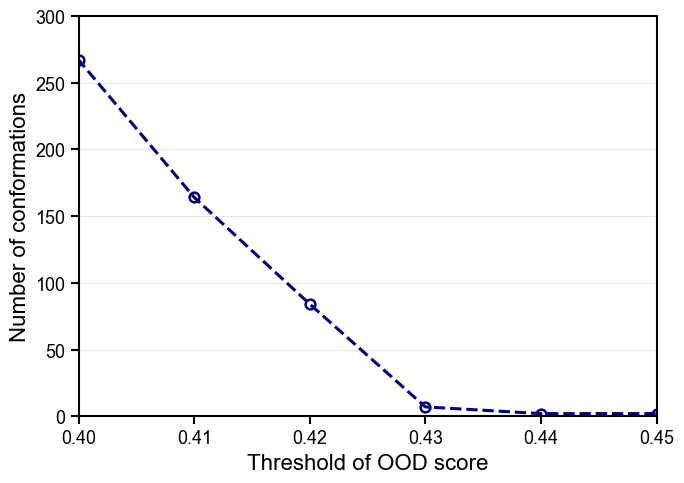

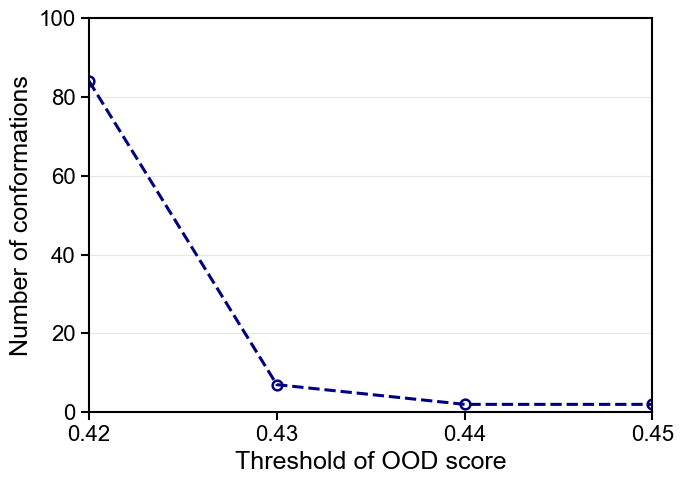

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# Flatten OOD scores
all_ood = np.concatenate(ood_scores)

# Define cutoffs with finer spacing
cutoffs = np.arange(0.05, 0.50, 0.01)

# Count conformations (OOD >= cutoff)
n_identified = np.array([(all_ood >= c).sum() for c in cutoffs])

# First zoomed plot
plt.figure(figsize=(7,5))
plt.plot(
    cutoffs,
    n_identified,
    color="navy",
    marker='o',
    markersize=7,
    markerfacecolor='none',
    markeredgewidth=1.8,
    linestyle='--',
    linewidth=2.2
)

plt.xlabel("Threshold of OOD score", fontsize=16)
plt.ylabel("Number of conformations", fontsize=16)
plt.xlim(0.40, 0.45)
plt.ylim(0, 300)
plt.xticks(np.arange(0.40, 0.451, 0.01))
plt.tick_params(axis='both', labelsize=13)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Second zoomed plot: start at 0.42
mask = cutoffs >= 0.42

plt.figure(figsize=(7,5))
plt.plot(
    cutoffs[mask],
    n_identified[mask],
#    color="#1f77b4",
    color="navy",
    marker='o',
    markersize=7,
    markerfacecolor='none',
    markeredgewidth=1.8,
    linestyle='--',
    linewidth=2.2
)

plt.xlabel("Threshold of OOD score", fontsize=18)
plt.ylabel("Number of conformations", fontsize=18)
plt.xlim(0.42, 0.45)
plt.ylim(0, 100)
plt.xticks(np.arange(0.42, 0.451, 0.01))
plt.tick_params(axis='both', labelsize=16)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
# Initialize the StateAnalyzer
analyzer = StateAnalyzer(state_centers, features, ood_scores)

# Find the closest frames to each state center
center_idx = 3
center_frames = analyzer.find_center_frames(center_idx=center_idx)
print(f"Closest frames to state center {center_idx}:")
print(center_frames.to_string(index=False))

Closest frames to state center 3:
 Center_Index  Trajectory  Frame  Flatten_Index
            3         981    950        1198357
            3         493   1707         621247
            3         109    178         146419
            3         542   1043         687283
            3         615      5         773561
            3         998    336        1221968
            3         335    803         421383
            3          82    304         110359
            3          26    125          39815
            3         111    134         148760


In [19]:
state_idx_1 = 0
state_idx_2 = 3
transition_states = analyzer.find_transition_states(state_idx_1, state_idx_2, threshold=0.5)
print(f"Transition state between state {state_idx_1} and state {state_idx_2}:")
print(transition_states.to_string(index=False))

Transition state between state 0 and state 3:
 State_1_Index  State_2_Index  OOD_Score  Flatten_Index  Trajectory  Frame
             0              3   0.425602        1071461         875    437
             0              3   0.426105         264853         212    650
             0              3   0.427660        1206302         987    390
             0              3   0.428483         264900         212    697
             0              3   0.428535         264798         212    595
             0              3   0.428716        1360027        1113      7
             0              3   0.428817        1206309         987    397
             0              3   0.428824         264895         212    692
             0              3   0.428971         264880         212    677
             0              3   0.430940         264887         212    684


In [20]:
state_idx_1 = 0
state_idx_2 = 2
transition_states = analyzer.find_transition_states(state_idx_1, state_idx_2, threshold=0.5)
print(f"Transition state between state {state_idx_1} and state {state_idx_2}:")
print(transition_states.to_string(index=False))

Transition state between state 0 and state 2:
 State_1_Index  State_2_Index  OOD_Score  Flatten_Index  Trajectory  Frame
             0              2   0.244042         502674         400     20
             0              2   0.263592        1188637         974     15
             0              2   0.284553        1188663         974     41
             0              2   0.322978        1271644        1041     94
             0              2   0.323787        1188627         974      5
             0              2   0.340591         502730         400     76
             0              2   0.349305        1188659         974     37
             0              2   0.360044        1188728         974    106
             0              2   0.381448         433006         342      1
             0              2   0.385300         502729         400     75


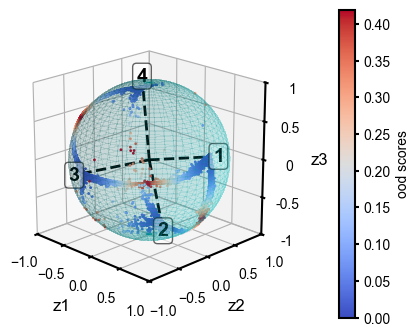

In [22]:
sim_mat = np.arccos(state_centers.dot(state_centers.T))
np.fill_diagonal(sim_mat, val=np.pi)
thres = -np.cos(sim_mat.min()/2) + 1
r = 1
pi = np.pi
cos = np.cos
sin = np.sin
phi, theta = np.mgrid[0.0:pi:100j, 0.0:2.0*pi:100j]
x = r*sin(phi)*cos(theta)
y = r*sin(phi)*sin(theta)
z = r*cos(phi)

plt.rcParams['figure.figsize'] = (5, 4)
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(
    x, y, z, rstride=2, cstride=2, color='c', alpha=0.1, linewidth=100, antialiased=False)

label_map = {0: '3', 1: '4', 2: '2', 3: '1'}
for i in range(4):
    ax.plot([0, state_centers[i,0]], [0, state_centers[i,1]], [0, state_centers[i,2]],
            linewidth=2, color='black', linestyle='--')
    ax.text(
        1.15 * state_centers[i,0],
        1.15 * state_centers[i,1],
        1.15 * state_centers[i,2],
        label_map[i],  # <-- was f"{i+1}"
        fontsize=14, ha="center", va="center",
        color="black", weight="bold",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.6)
    )
#    ax.text(
#        1.15 * state_centers[i,0],
#        1.15 * state_centers[i,1],
#        1.15 * state_centers[i,2],
#        f"{i+1}",
#        fontsize=14, ha="center", va="center",
#        color="black", weight="bold",
#        bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.6)
#    )

cb = ax.scatter(np.concatenate(features)[:,0],
                np.concatenate(features)[:,1],
                np.concatenate(features)[:,2],
                c=np.concatenate(ood_scores), s=1, alpha=1, cmap='coolwarm')
cb.set_clim(0.0, thres)
ccc = fig.colorbar(cb, pad=0.15)
ccc.ax.tick_params(labelsize=10, length=3, width=1.5)
ccc.set_label('ood scores', fontsize=10)

ax.set_xlim([-1, 1])
ax.set_ylim([-1, 1])
ax.set_zlim([-1, 1])
ax.set_xticks([-1, -0.5, 0, 0.5, 1])
ax.set_yticks([-1, -0.5, 0, 0.5, 1])
ax.set_zticks([-1, -0.5, 0, 0.5, 1], [-1, -0.5, 0, 0.5, 1])
ax.set_aspect("equal")
ax.tick_params(axis="both", labelsize=10, direction='out', length=7.5, width=2.5)
ax.set_xlabel('z1', fontsize=12)
ax.set_ylabel('z2', fontsize=12)
ax.set_zlabel('z3', fontsize=12)
#ax.view_init(elev=40, azim=-60)
ax.view_init(elev=20, azim=-45)

plt.show()

In [24]:
from collections import Counter
state_counts = Counter(np.concatenate(lumped_trajs))
print(state_counts)


Counter({3: 636297, 1: 462509, 0: 338931, 2: 69983})


In [25]:
from msmbuilder.msm import MarkovStateModel
n_macro = 4
def generate_TCM(trajs, lagtime, n_macro):
    # Users can adjust the setting of the MarkovStateModel
    TCM = np.zeros((len(lagtime), n_macro, n_macro))
    for i in range(len(lagtime)):
        msm_macro = MarkovStateModel(n_timescales=3, lag_time=lagtime[i],
                                     ergodic_cutoff='off',
                                     reversible_type='None',
                                     verbose=False)
        msm_macro.fit(trajs)
        TCM[i] = np.array(msm_macro.countsmat_)
    return TCM

#n_macro = 4 # number of macrostates
TCM = generate_TCM(trajs = lumped_trajs, lagtime = np.arange(1, 401), n_macro = 4)
#print(TPM.shape)
print(TCM.shape)
print(TCM)

(400, 4, 4)
[[[3.38286000e+05 2.97000000e+02 1.30000000e+01 6.30000000e+01]
  [3.22000000e+02 4.61779000e+05 1.40000000e+01 2.00000000e+00]
  [1.40000000e+01 1.40000000e+01 6.98720000e+04 3.40000000e+01]
  [8.50000000e+01 3.00000000e+00 3.60000000e+01 6.35652000e+05]]

 [[1.69003000e+05 1.51000000e+02 6.50000000e+00 3.35000000e+01]
  [1.74500000e+02 2.30679500e+05 7.00000000e+00 1.00000000e+00]
  [7.00000000e+00 7.50000000e+00 3.49075000e+04 2.05000000e+01]
  [5.05000000e+01 2.00000000e+00 2.25000000e+01 3.17552500e+05]]

 [[1.12578333e+05 1.00666667e+02 4.00000000e+00 2.23333333e+01]
  [1.19666667e+02 1.53650667e+05 6.33333333e+00 6.66666667e-01]
  [6.00000000e+00 5.00000000e+00 2.32536667e+04 1.40000000e+01]
  [3.83333333e+01 1.66666667e+00 1.63333333e+01 2.11521667e+05]]

 ...

 [[5.86670854e+02 2.46231156e-01 2.51256281e-02 4.52261307e-02]
  [4.93467337e+00 7.72447236e+02 7.78894472e-02 0.00000000e+00]
  [3.76884422e-02 3.26633166e-02 1.26688442e+02 6.28140704e-02]
  [1.84422111e+0

In [26]:
from msmbuilder.msm import MarkovStateModel

n_states = 4
num_runs = 50
num_samples_per_run = 1234
lt = np.arange(450, 5501, 450)
def generate_TPM(trajs, lagtime, n_states=4,):
    TPM = []
    for i in range(len(lagtime)):
        msm_macro = MarkovStateModel(n_timescales=3, lag_time=lagtime[i],
                                     ergodic_cutoff='off', reversible_type='transpose', verbose=False)
        msm_macro.fit(trajs)
        if len(msm_macro.transmat_) != n_states:
            return None
        TPM.append(msm_macro.transmat_)
    return np.array(TPM)

bootstrap_TPM = np.zeros((num_runs, len(lt), n_states, n_states))
for i in range(num_runs):
    bootstrap_indices = np.random.choice(range(len(lumped_trajs)), size=num_samples_per_run, replace=True)
    bootstrap_trajs = [lumped_trajs[i] for i in bootstrap_indices]
    temp_TPM = generate_TPM(bootstrap_trajs, lagtime=lt)
    if temp_TPM is None:
        continue
    bootstrap_TPM[i] = temp_TPM
    print('Run {} is complete'.format(i))

/Users/eshanig/miniforge3/envs/msm/lib/python3.9/site-packages/msmbuilder/msm/msm.py:194: RuntimeWarning: invalid value encountered in divide
  populations /= populations.sum(dtype=float)
/Users/eshanig/miniforge3/envs/msm/lib/python3.9/site-packages/msmbuilder/msm/msm.py:195: RuntimeWarning: invalid value encountered in divide
  transmat = rev_counts.astype(float) / rev_counts.sum(axis=1)[:, None]


Run 0 is complete
Run 1 is complete
Run 2 is complete
Run 3 is complete
Run 4 is complete
Run 5 is complete
Run 6 is complete
Run 7 is complete
Run 8 is complete
Run 9 is complete
Run 10 is complete
Run 11 is complete
Run 12 is complete
Run 13 is complete
Run 14 is complete
Run 15 is complete
Run 16 is complete
Run 17 is complete
Run 18 is complete
Run 19 is complete
Run 20 is complete
Run 21 is complete
Run 22 is complete
Run 23 is complete
Run 24 is complete
Run 25 is complete
Run 26 is complete
Run 27 is complete
Run 28 is complete
Run 29 is complete
Run 30 is complete
Run 31 is complete
Run 32 is complete
Run 33 is complete
Run 34 is complete
Run 35 is complete
Run 36 is complete
Run 37 is complete
Run 38 is complete
Run 39 is complete
Run 40 is complete
Run 41 is complete
Run 42 is complete
Run 43 is complete
Run 44 is complete
Run 45 is complete
Run 46 is complete
Run 47 is complete
Run 48 is complete
Run 49 is complete


In [27]:
lagtime = 450

msm = MarkovStateModel(n_timescales=6, lag_time=lagtime, ergodic_cutoff='off', 
                       reversible_type='transpose', verbose=False)
msm.fit(lumped_trajs)
transmat = msm.transmat_

order_parameter = np.arange(1, int(5501 / lagtime + 1))
#order_parameter = np.arange(1, len(lt) + 1)
#msm_time = order_parameter * lagtime * 0.2
msm_time = order_parameter * lagtime # ns
msm_TPM = []
for i in order_parameter:
    msm_TPM.append(np.linalg.matrix_power(transmat, i))
msm_TPM = np.array(msm_TPM)

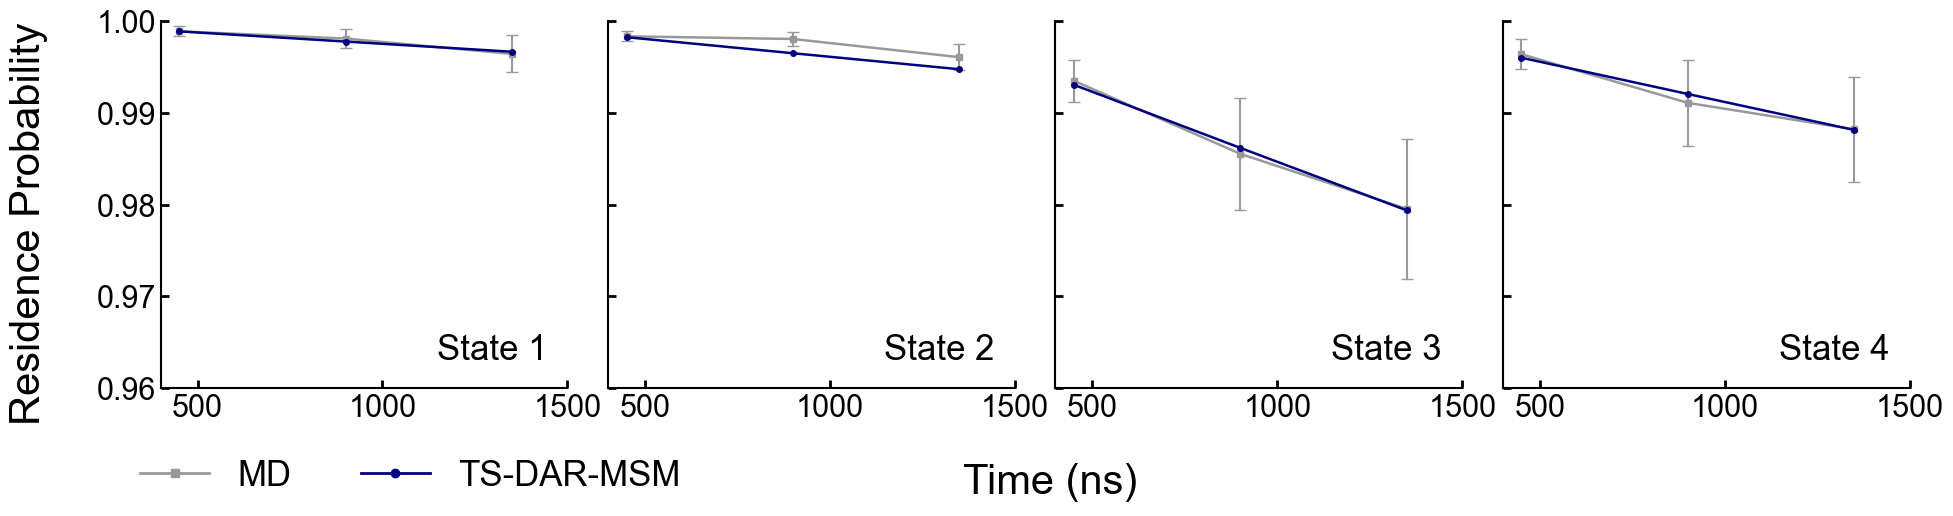

In [31]:
from matplotlib.lines import Line2D
plt.rcParams['font.size'] = 17.5
plt.rcParams['axes.linewidth'] = 2

TPM_mean = np.mean(bootstrap_TPM, axis=0)
TPM_std = np.std(bootstrap_TPM, axis=0)

color_msm = '#D55E00'
color_md = '#999999'
label_map = {0: '3', 1: '4', 2: '2', 3: '1'}

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharex=True, sharey=True)

plot_order = [3, 2, 0, 1]

for plot_i, i in enumerate(plot_order):
    ax = axes[plot_i]
    ax.errorbar(x=lt[:3], y=TPM_mean[:3, i, i], yerr=TPM_std[:3, i, i],
                fmt='s-', capsize=4, elinewidth=1.5, markersize=4,
                linewidth=1.8, color=color_md, ecolor=color_md, zorder=1)
    ax.plot(msm_time[:3], msm_TPM[:3, i, i],
            color='navy', linewidth=1.8,
            marker='o', markersize=4, zorder=3)
    ax.text(0.95, 0.15, f'State {label_map[i]}', ha='right', va='top',
            transform=ax.transAxes, fontsize=25)
    ax.set_ylim(0.96, 1.00)
    ax.set_xlim(400, 1500)
    ax.set_xticks([500, 1000, 1500])
    ax.tick_params(axis='both', direction='in', width=2, length=6, labelsize=22)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_linewidth(1.5)
    # Only show y-axis tick labels on the first panel
    if plot_i > 0:
        ax.tick_params(labelleft=False)

fig.text(0.54, -0.04, 'Time (ns)', ha='center', fontsize=30)
fig.text(0.02, 0.5, 'Residence Probability', va='center', rotation='vertical', fontsize=30)

legend_handles = [
    Line2D([0], [0], color=color_md, linewidth=2, marker='s', markersize=6, label='MD'),
    Line2D([0], [0], color='navy', linewidth=2, marker='o', markersize=6, label='TS-DAR-MSM'),
]
fig.legend(handles=legend_handles, fontsize=25, frameon=False,
           loc='lower center', bbox_to_anchor=(0.22, -0.1), ncol=2)

plt.tight_layout(rect=[0.05, 0.05, 1, 0.98])
plt.subplots_adjust(wspace=0.1)

plt.show()

In [32]:
resi = []
lt = np.arange(1, 451, 1)
timescales = np.zeros((len(lt), 3))
for i in range(len(lt)):
    msm = MarkovStateModel(n_timescales=3, lag_time=lt[i], ergodic_cutoff='off', 
                       reversible_type='transpose', verbose=False)
    msm.fit(lumped_trajs)
    timescales[i] = msm.timescales_[:3]
    resi.append(np.diag(msm.transmat_))

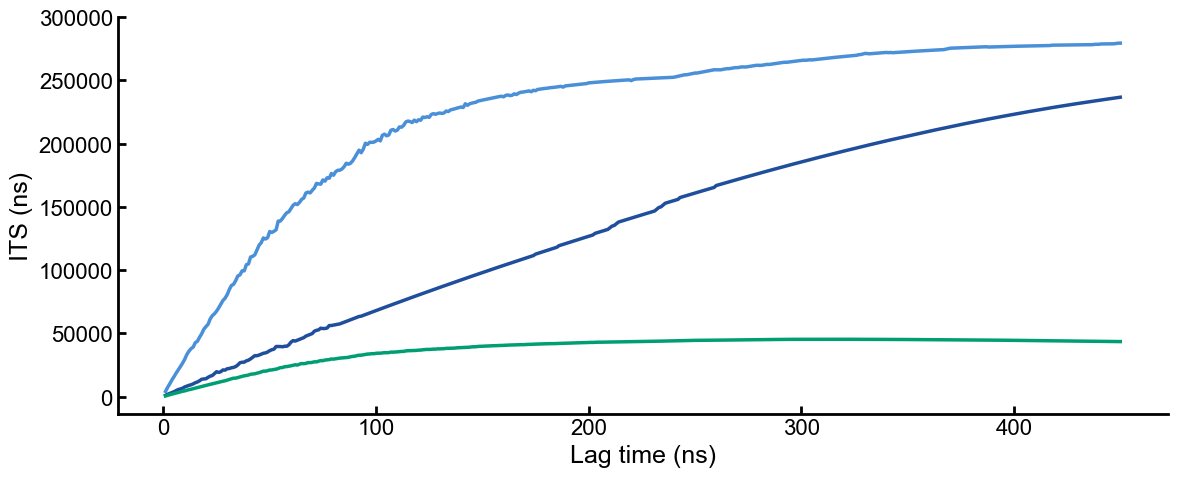

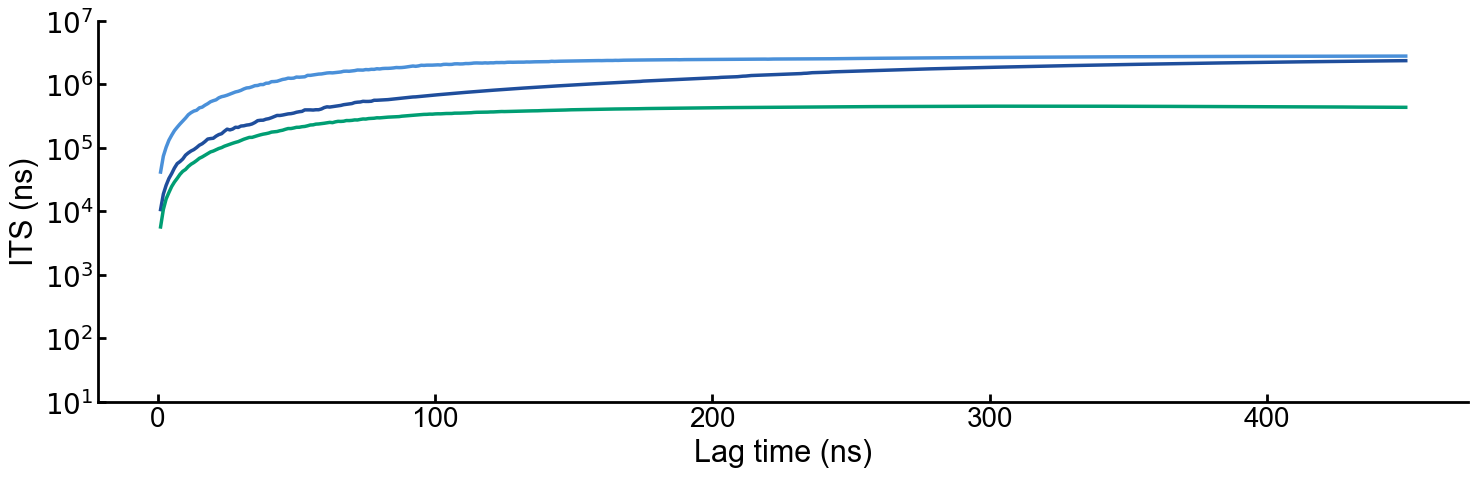

In [33]:
import numpy as np
from matplotlib import pyplot as plt

plt.rcParams.update({
    "font.family":       "Arial",
    "font.size":          14,
    "axes.linewidth":     2,
    "xtick.major.width":  2,
    "ytick.major.width":  2,
    "xtick.major.size":   6,
    "ytick.major.size":   6,
})

colors = ['#4A90D9', '#1F4E9C', '#009E73']

# linear ITS
fig, ax = plt.subplots(figsize=(12, 5))
for k, c in enumerate(colors):
    ax.plot(lt, timescales[:, k], color=c, linewidth=2.5, label=f'ITS {k+1}')

ax.set_xlabel('Lag time (ns)', fontsize=18)
ax.set_ylabel('ITS (ns)', fontsize=18)
ax.set_yticks([0, 50000, 100000, 150000, 200000, 250000, 300000])
ax.tick_params(axis='both', direction='in', labelsize=16)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

plt.show()

# log ITS
fig, ax = plt.subplots(figsize=(15, 5))
for k, c in enumerate(colors):
    ax.plot(lt, np.log10(timescales[:, k]), color=c, linewidth=2.5, label=f'ITS {k+1}')

ax.set_yticks([0, 1, 2, 3, 4, 5, 6])
ax.set_yticklabels(["$10^1$", "$10^2$", "$10^3$", "$10^4$", "$10^5$", "$10^6$", "$10^7$"])

ax.set_xlabel('Lag time (ns)', fontsize=22)
ax.set_ylabel('ITS (ns)', fontsize=22)
ax.tick_params(axis='both', direction='in', labelsize=20)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

plt.show()

In [34]:
#MFPT

from msmbuilder.tpt import *
lagtime = [1, 10, 50, 100, 200, 300, 400, 450, 500]

for i in range(len(lagtime)):
    print(f"Lagtime =",lagtime[i])
    msm = MarkovStateModel(n_timescales=3, lag_time=lagtime[i], ergodic_cutoff='off',reversible_type='transpose',verbose=False)
    msm_macro = msm.fit(lumped_trajs)
    MFPT = mfpts(msm_macro,sinks=None)
    MFPT_in_ns = MFPT*lagtime[i]
    MFPT_in_us = MFPT_in_ns/1000
    #print(MFPT)
    #print(MFPT_in_ns)
    print(f'{MFPT_in_us}\n')

Lagtime = 1
[[ 0.          2.96168921 23.90459282  8.91414654]
 [ 1.72119281  0.         24.28176282 10.10845143]
 [ 5.725668    7.34333441  0.          5.30870077]
 [ 7.53780145  9.97260274 22.1112805   0.        ]]

Lagtime = 10
[[  0.          24.19739798 173.82605162  62.07332287]
 [ 14.07616827   0.         176.50579382  71.85706479]
 [ 42.20275849  55.0037304    0.          36.34109839]
 [ 53.0578773   72.96284893 158.94894595   0.        ]]

Lagtime = 50
[[  0.         112.59868284 822.43902809 272.81073513]
 [ 65.1222848    0.         831.7697845  318.70622743]
 [192.88432767 249.69148212   0.         161.46349199]
 [233.90828018 327.28017052 752.11573746   0.        ]]

Lagtime = 100
[[   0.          189.13743435 1528.94203917  414.34017036]
 [ 104.93895178    0.         1546.41163235  493.21972649]
 [ 315.20247937  416.87055511    0.          251.36691931]
 [ 355.05797195  518.13601065 1405.8242807     0.        ]]

Lagtime = 200
[[   0.          246.92800345 2771.36742683  4

In [35]:
#TPT

lagtime = [1, 10, 50, 100, 200, 300, 450, 500]

print(np.arange(4))

source = 1
sink = 3
for i in range(len(lagtime)):
    print(f"Lagtime =",lagtime[i])
    msm = MarkovStateModel(n_timescales=3, lag_time=lagtime[i], ergodic_cutoff='off',reversible_type='transpose',verbose=False)
    msm_macro = msm.fit(lumped_trajs)
    FLUXES = fluxes(source,sink,msm_macro)
    NET_FLUXES = net_fluxes(source,sink,msm_macro)
    PATHS, PATH_FLUXES = paths(source,sink,NET_FLUXES)
    #print(FLUXES)
    print(PATHS[0])
    print(f'{PATH_FLUXES}\n')

[0 1 2 3]
Lagtime = 1
[1 0 3]
[3.89548190e-05 5.61960079e-06 3.56427161e-06 1.65949103e-06]

Lagtime = 10
[1 0 3]
[5.45081532e-05 8.35974892e-06 4.17719596e-06 2.00617903e-06]

Lagtime = 50
[1 0 3]
[6.23645688e-05 9.58405323e-06 3.72350514e-06 1.72888342e-06]

Lagtime = 100
[1 0 3]
[8.30922802e-05 1.03510716e-05 3.62788415e-06 1.80594082e-06]

Lagtime = 200
[1 0 3]
[1.42519197e-04 1.14010054e-05 3.68345087e-06 1.98122590e-06]

Lagtime = 300
[1 0 3]
[2.04911370e-04 1.21735747e-05 3.80899611e-06 2.19056131e-06]

Lagtime = 450
[1 0 3]
[3.04804185e-04 1.43372324e-05 4.72368827e-06 2.59190372e-06]

Lagtime = 500
[1 0 3]
[3.41112807e-04 1.09661293e-05 5.66587685e-06 2.19842549e-06]



In [39]:
import numpy as np
from msmbuilder.msm import MarkovStateModel
from msmbuilder.tpt import fluxes, net_fluxes, paths

lagtimes = [450, 500]

n_states   = 4
flux_cover = 1  

for tau in lagtimes:
    print("\n" + "="*60)
    print(f"Lagtime = {tau}")
    print("="*60)

    # --- build MSM at this lagtime ---
    msm = MarkovStateModel(
        n_timescales=3,
        lag_time=tau,
        ergodic_cutoff='off',
        reversible_type='transpose',
        verbose=False,
    )
    msm_macro = msm.fit(lumped_trajs)

    all_paths = {}  # reset for this tau: (source, sink) -> list of paths

    # loop over all ordered source/sink pairs
    for source in range(n_states):
        for sink in range(n_states):
            if source == sink:
                continue

            NF = net_fluxes(source, sink, msm_macro)
            PATHS, PATH_FLUXES = paths(source, sink, NF)

            if len(PATHS) == 0 or PATH_FLUXES.sum() == 0:
                print(f"\n=== Source {source} → Sink {sink} ===")
                print("No reactive flux")
                all_paths[(source, sink)] = []
                continue

            total_flux = PATH_FLUXES.sum()
            cum_flux   = 0.0
            pair_paths = []

            print(f"\nSource {source} → Sink {sink}")
            for k, (p, f) in enumerate(zip(PATHS, PATH_FLUXES)):
                frac = f / total_flux
                cum_flux += frac

                print(f"Path {k}: {p}   flux = {f:.3g}   ({frac*100:.1f}% of reactive flux)")

                pair_paths.append({
                    "path": p,
                    "flux": f,
                    "frac": frac,
                })

                # stop once we cover 'flux_cover' fraction of the total reactive flux
                if cum_flux >= flux_cover:
                    break

            all_paths[(source, sink)] = pair_paths



Lagtime = 450

Source 0 → Sink 1
Path 0: [0 1]   flux = 0.00117   (98.4% of reactive flux)
Path 1: [0 3 2 1]   flux = 1.27e-05   (1.1% of reactive flux)
Path 2: [0 2 1]   flux = 3.67e-06   (0.3% of reactive flux)
Path 3: [0 3 1]   flux = 2.5e-06   (0.2% of reactive flux)

Source 0 → Sink 2
Path 0: [0 3 2]   flux = 4.55e-05   (56.1% of reactive flux)
Path 1: [0 1 2]   flux = 2.24e-05   (27.6% of reactive flux)
Path 2: [0 2]   flux = 1.3e-05   (16.0% of reactive flux)
Path 3: [0 1 3 2]   flux = 2.34e-07   (0.3% of reactive flux)

Source 0 → Sink 3
Path 0: [0 3]   flux = 0.000414   (94.6% of reactive flux)
Path 1: [0 1 2 3]   flux = 1.32e-05   (3.0% of reactive flux)
Path 2: [0 2 3]   flux = 7.68e-06   (1.8% of reactive flux)
Path 3: [0 1 3]   flux = 2.56e-06   (0.6% of reactive flux)

Source 1 → Sink 0
Path 0: [1 0]   flux = 0.00117   (98.4% of reactive flux)
Path 1: [1 2 3 0]   flux = 1.27e-05   (1.1% of reactive flux)
Path 2: [1 2 0]   flux = 3.67e-06   (0.3% of reactive flux)
Path 3:

In [40]:
import numpy as np
from msmbuilder.tpt import fluxes, net_fluxes, paths
lagtime = [1, 10, 50, 100, 200, 300, 450, 500]
msm = MarkovStateModel(n_timescales=3, lag_time=lagtime[i], ergodic_cutoff='off',reversible_type='transpose',verbose=False)
msm_macro = msm.fit(lumped_trajs)
n_states = 4
flux_cover = 0.8  # cover 90% of total reactive flux

all_paths = {}  # (i,j) -> list of dicts: [{'path':..., 'flux':..., 'frac':...}, ...]

for source in range(n_states):
    for sink in range(n_states):
        if source == sink:
            continue

        NF = net_fluxes(source, sink, msm_macro)
        PATHS, PATH_FLUXES = paths(source, sink, NF)

        if len(PATHS) == 0 or PATH_FLUXES.sum() == 0:
            print(f"No reactive flux from {source} → {sink}")
            all_paths[(source, sink)] = []
            continue

        total_flux = PATH_FLUXES.sum()
        cum_flux = 0.0
        pair_paths = []

        print(f"\nSource {source} → Sink {sink}")
        for k, (p, f) in enumerate(zip(PATHS, PATH_FLUXES)):
            frac = f / total_flux
            cum_flux += frac

            print(f"Path {k}: {p}   flux = {f:.3g}   ({frac*100:.1f}% of reactive flux)")

            pair_paths.append({
                "path": p,
                "flux": f,
                "frac": frac,
            })

            if cum_flux >= flux_cover:
                break

        all_paths[(source, sink)] = pair_paths



Source 0 → Sink 1
Path 0: [0 1]   flux = 0.00134   (98.9% of reactive flux)

Source 0 → Sink 2
Path 0: [0 3 2]   flux = 4.76e-05   (62.0% of reactive flux)
Path 1: [0 1 2]   flux = 1.57e-05   (20.5% of reactive flux)

Source 0 → Sink 3
Path 0: [0 3]   flux = 0.00046   (95.7% of reactive flux)

Source 1 → Sink 0
Path 0: [1 0]   flux = 0.00134   (98.9% of reactive flux)

Source 1 → Sink 2
Path 0: [1 0 3 2]   flux = 4.54e-05   (61.1% of reactive flux)
Path 1: [1 2]   flux = 1.59e-05   (21.5% of reactive flux)

Source 1 → Sink 3
Path 0: [1 0 3]   flux = 0.000341   (94.8% of reactive flux)

Source 2 → Sink 0
Path 0: [2 3 0]   flux = 4.76e-05   (62.0% of reactive flux)
Path 1: [2 1 0]   flux = 1.57e-05   (20.5% of reactive flux)

Source 2 → Sink 1
Path 0: [2 3 0 1]   flux = 4.54e-05   (61.1% of reactive flux)
Path 1: [2 1]   flux = 1.59e-05   (21.5% of reactive flux)

Source 2 → Sink 3
Path 0: [2 3]   flux = 5.33e-05   (66.2% of reactive flux)
Path 1: [2 1 0 3]   flux = 1.47e-05   (18.2% of